LangChain1.x 的短期记忆是三者的组合：

State（会话内部状态） + Checkpointer（持久化机制） + Thread ID（会话作用域）
- State ：默认 存储历史消息列表messages ，通过State 管理历史消息
- Checkpointer ：负责将State 作为检查点持久化保存，检查点是某个时刻的State 快照
- Thread ID ：用于唯一标识State ，LangChain运行时会按照 thread_id 读写State快照

> 这就像玩 RPG 游戏时的“自动存档”：你不需要手动保存，系统在关键节点自动记录，下次进入游戏随时可以从上次的存档点继续。

## 1、基于内存的持久化器

这是最便捷的使用方式，适合快速测试或调试。

### 1.1 举例1:没有记忆

In [7]:
import os

from dotenv import load_dotenv
from langchain.chat_models import init_chat_model

load_dotenv(override=True)

model = init_chat_model(
    model="deepseek-flash",
    model_provider="deepseek",
    api_key=os.getenv("DEEPSEEK_API_KEY"),
    base_url=os.getenv("DEEPSEEK_BASE_URL")
)

In [2]:
from langchain_core.messages import HumanMessage
from langchain.agents import create_agent

agent = create_agent(
    model=model,
    tools=[]
)

print("\n第一轮对话：")
response1 = agent.invoke({
    "messages": [HumanMessage("我叫张三")]
})
print(f"Agent: {response1['messages'][-1].content}")

print("\n第二轮对话：")
response2 = agent.invoke({
    "messages": [HumanMessage("我叫什么？")]
})
print(f"Agent: {response2['messages'][-1].content}")


第一轮对话：
Agent: 你好，张三！很高兴认识你。有什么我可以帮你的吗？

第二轮对话：
Agent: 我不知道你的名字——在我们的对话里你没有告诉过我。你可以直接告诉我你希望我怎么称呼你。


### 1.2 举例2:拥有记忆

步骤1:第一二轮对话

In [3]:
from langgraph.checkpoint.memory import InMemorySaver

checkPointer = InMemorySaver()

agent = create_agent(
    model=model,
    checkpointer=checkPointer,
)

config = {
    "configurable": {"thread_id": "1"}
}

print("\n第一轮对话：")
response1 = agent.invoke({
    "messages": [HumanMessage("我叫张三")]},
    config=config # 传入 config
)
print(f"Agent: {response1['messages'][-1].content}")

print("\n第二轮对话：")
response2 = agent.invoke({
    "messages": [HumanMessage("我叫什么？")]},
    config=config # 使用相同的 thread_id
)
print(f"Agent: {response2['messages'][-1].content}")


第一轮对话：
Agent: 你好，张三！很高兴认识你。有什么我可以帮你的吗？

第二轮对话：
Agent: 你叫张三。


说明：你只需传入 checkpointer 和 config，Agent 就能自然具备连续对话能力。

In [4]:
from rich import print as rprint

latest_state = agent.get_state(config)
rprint(latest_state)

StateSnapshot(
    values={
        'messages': [
            HumanMessage(
                content='我叫张三',
                additional_kwargs={},
                response_metadata={},
                id='ea7bd2c2-32f8-49df-8a56-f38fac5e004c'
            ),
            AIMessage(
                content='你好，张三！很高兴认识你。有什么我可以帮你的吗？',
                additional_kwargs={
                    'refusal': None,
                    'reasoning_content': 
'我们需要回答中文。用户说“我叫张三”。简单回应，可能问候。需要根据上下文？没有。应该礼貌自我介绍/回应。可以说“你好，
张三！很高兴认识你。有什么我可以帮你的吗？” 保持简洁。'
                },
                response_metadata={
                    'token_usage': {
                        'completion_tokens': 63,
                        'prompt_tokens': 32,
                        'total_tokens': 95,
                        'completion_tokens_details': {
                            'accepted_prediction_tokens': None,
                            'audio_tokens': None,
                            'reasoning_tokens': 48,
                            'rejected_prediction_tokens': None,
                            'text_tokens': None
                        },
                        'prompt_tokens_details': {
                            'audio_tokens': None,
                            'cache_write_tokens': None,
                            'cached_tokens': 0,
                            'image_tokens': None,
                            'text_tokens': None
                        },
                        'prompt_cache_hit_tokens': 0,
                        'prompt_cache_miss_tokens': 32
                    },
                    'model_provider': 'deepseek',
                    'model_name': 'deepseek-flash',
                    'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6',
                    'id': 'cc4574e1-14e7-4cf0-85ec-703af8e0e938',
                    'finish_reason': 'stop',
                    'logprobs': None
                },
                id='lc_run--01a1f923-34a4-70e2-af30-bdfdf4cbdf7c-0',
                tool_calls=[],
                invalid_tool_calls=[],
                usage_metadata={
                    'input_tokens': 32,
                    'output_tokens': 63,
                    'total_tokens': 95,
                    'input_token_details': {'cache_read': 0},
                    'output_token_details': {'reasoning': 48}
                }
            ),
            HumanMessage(
                content='我叫什么？',
                additional_kwargs={},
                response_metadata={},
                id='362959f4-8731-4f6a-85c3-3f7883cc354d'
            ),
            AIMessage(
                content='你叫张三。',
                additional_kwargs={
                    'refusal': None,
                    'reasoning_content': 
'我们需要回答用户中文问题。上下文：用户说“我叫张三”，然后问“我叫什么？”需要回答“你叫张三”。简单。注意可能这是一个测
试记忆。直接。'
                },
                response_metadata={
                    'token_usage': {
                        'completion_tokens': 42,
                        'prompt_tokens': 53,
                        'total_tokens': 95,
                        'completion_tokens_details': {
                            'accepted_prediction_tokens': None,
                            'audio_tokens': None,
                            'reasoning_tokens': 37,
                            'rejected_prediction_tokens': None,
                            'text_tokens': None
                        },
                        'prompt_tokens_details': {
                            'audio_tokens': None,
                            'cache_write_tokens': None,
                            'cached_tokens': 0,
                            'image_tokens': None,
                            'text_tokens': None
                        },
                        'prompt_cache_hit_tokens': 0,
                        'prompt_cache_miss_tokens': 53
                    },
                    'model_provider': 'deepseek',
                    'model_name': 'deepseek-flash',
         

步骤2:第三轮对话

当我们再次进行对话时，直接带入线程ID，即可带入此前对话记忆。

In [5]:
print("\n第三轮对话：")
response3 = agent.invoke({
    "messages": [HumanMessage("我刚才问了什么问题？")]},
    config=config
)
print(f"Agent: {response3['messages'][-1].content}")


第三轮对话：
Agent: 你刚才问的是：“我叫什么？”


说明：第三轮对话中的 "我刚才问了什么问题？" 就能在第二轮存储的消息历史中找到答案。所有消息历史都会自动追加到 AgentState 的 messages 字段中，无需手动维护。

步骤3:更新线程ID

而如果更新线程ID，则会重新开启对话：

In [6]:
config2 = {
    "configurable": {
        "thread_id": "2"
    }
}

response4 = agent.invoke({"messages": [HumanMessage("你还记得我叫什么名字么？")]}, config=config2)
print(response4['messages'][-1].content)

抱歉，我无法记得你的名字——当前对话里我没有你的个人信息或之前的记忆。你可以告诉我你希望我怎么称呼你。


说明：thread_id 隔离不同会话空间。

### 1.3 关键步骤说明

第一步：初始化记忆引擎：`checkpointer = InMemorySaver()`---创建内存级的记忆存储。

> 注意：InMemorySaver内存中保存，进程结束就丢失数据，适合测试。生产环境可换成数据库持久化的SqliteSaver、PostgresSaver等。

第二步：绑定Agent：在`create_agent`时传入checkpointer，让Agent具备状态存储能力。

第三步：设定会话ID：通过`config = {"configurable": {"thread_id": "1"}}`为每次调用指定线程标识。同一个thread_id共享记忆，不同thread_id完全隔离。

```
# 会话 1
config1 = {"configurable": {"thread_id": "1"}}
agent.invoke({...}, config=config1)

# 会话 2
config2 = {"configurable": {"thread_id": "2"}}
agent.invoke({...}, config=config2)

# 两个会话完全独立
```

thread_id 是记忆管理的核心开关：在会话2里询问会话1的会话信息，Agent 会表示不知道——因为双方记忆空间完全隔离。

生产环境中：

**场景1:多用户聊天**

不同 thread_id = 不同会话，Agent 能正确记住每个会话的内容。

```
agent = create_agent(
    model=model,
    tools=[],
    checkpointer=InMemorySaver()
)

# 用户 Alice
config_alice = {"configurable": {"thread_id": "user_alice"}}
agent.invoke({"messages": [...]}, config_alice)
...

# 用户 Bob
config_bob = {"configurable": {"thread_id": "user_bob"}}
agent.invoke({"messages": [...]}, config_bob)
...

# 两个会话完全独立
```

**场景2：同一用户的不同任务**

```
# 任务 1：写代码
config_task1 = {"configurable": {"thread_id": "task_coding"}}
agent.invoke({"messages": [...]}, config_task1)
...

# 任务 2：写文档
config_task2 = {"configurable": {"thread_id": "task_docs"}}
agent.invoke({"messages": [...]}, config_task2)
...
```

### 1.4 工作原理

内存保存了什么？

```
agent.invoke({"messages": [{"role": "user", "content": "你好"}]}, config)
# InMemorySaver 保存：
# {
#   "thread_id": "xxx",
#   "messages": [
#       HumanMessage("你好"),
#       AIMessage("你好！有什么可以帮助你的吗？")
#   ]
# }

agent.invoke({"messages": [{"role": "user", "content": "天气"}]}, config)
# InMemorySaver 更新：
# {
#   "thread_id": "xxx",
#   "messages": [
#       HumanMessage("你好"),
#       AIMessage("你好！有什么可以帮助你的吗？"),
#       HumanMessage("天气"),
#       AIMessage("...")
#   ]
# }
```

自动追加历史

```
# 你只需要传新消息
agent.invoke(
    {"messages": [{"role": "user", "content": "新问题"}]},
    config
)
```
此时，checkpointer自动：
1. 读取之前的历史。
2. 追加新消息。
3. 调用模型（传入完整历史）
4. 保存新的历史。

说明：checkpointer 会自动管理历史

### 1.5 常见问题

1、**为什么Agent不记得**

检查：
- ✅ 是否添加了 checkpointer=InMemorySaver() ？
- ✅ 是否传入了 config 参数？
- ✅ 两次调用的 thread_id 是否相同？

```
# ❌ 错误：没有 checkpointer
agent = create_agent(model=model, tools=[])
agent.invoke({...}) # 不会记住

# ❌ 错误：没有 config
agent = create_agent(model=model, tools=[], checkpointer=InMemorySaver())
agent.invoke({...}) # 不会记住

# ❌ 错误：thread_id 不同
agent.invoke({...}, config={"configurable": {"thread_id": "1"}})
agent.invoke({...}, config={"configurable": {"thread_id": "2"}}) # 不同会话

# ✅ 正确
agent = create_agent(model=model, tools=[], checkpointer=InMemorySaver())
config = {"configurable": {"thread_id": "1"}}
agent.invoke({...}, config)
agent.invoke({...}, config) # 记得！
```
2、**InMemorySaver会丢失数据吗**

会！ InMemorySaver 只保存在内存中：
- ✅ 同一进程内有效（不支持跨进程共享）
- ❌ 程序重启后丢失（或进程重启后丢失）
- ❌ 不同进程无法共享

解决方案：持久化（SQLite、PostgreSQL）

3、**内存会无限增长吗**

会！ 默认情况下，InMemorySaver 会保存所有消息。

问题：
- 消息越来越多（无限增长，需要管理上下文）
- token消耗增加，甚至会超过模型的 token 限制
- 响应速度变慢、成本增加

解决方案：上下文管理（修剪、摘要）

4、**如何清空某个会话的历史**

目前 InMemorySaver 没有提供删除 API。

临时方案：
- 使用新的 thread_id
- 或重新创建 Agent

## 2、基于外部存储介质的持久化器

如果将 状态检查点(checkpointer) 保存在内存， 进程结束 则状态丢失，生产环境不可接受。因此，生产环境要用持久化的外部存储介质，如PostgreSQL。LangGraph提供的checkpointer后端列表如下

https://docs.langchain.com/oss/python/langgraph/persistence#checkpointer-libraries

此处选择PostgreSQL作为持久化器。

### 2.1 环境准备

- 安装postgresql数据库。
- 安装langgraph-checkpoint-postgres依赖。
- 安装python -m pip install "psycopg[binary]"

### 2.2 代码实现

In [10]:
from langgraph.checkpoint.postgres import PostgresSaver

DB_URL="postgresql://" + os.getenv("POSTGRESQL_USER") + ":" + os.getenv("POSTGRESQL_PASSWORD") + "@localhost:5432/" + os.getenv("POSTGRESQL_DB") + "?sslmode=disable"

with PostgresSaver.from_conn_string(DB_URL) as checkPointer:
    # 初始化postgresql数据库
    checkPointer.setup()
    agent = create_agent(
        model=model,
        checkpointer=checkPointer
    )

    config = {"configurable": {"thread_id": "1"}}
    response1 = agent.invoke(
        {"messages": [HumanMessage("hello，我是帅哥。")]},
        config=config
    )
    print("=" * 30, "-> 第一次调用 <-", "=" * 30)
    for msg in response1["messages"]:
        msg.pretty_print()

    response2 = agent.invoke(
        {"messages": [HumanMessage("你好，我是谁？")]},
        config=config
    )
    print("=" * 30, "-> 第二次调用 <-", "=" * 30)
    for msg in response2["messages"]:
        msg.pretty_print()

============================== -> 第一次调用 <- ==============================
================================ Human Message =================================

hello，我是帅哥。
================================== Ai Message ==================================

你好呀，帅哥！很高兴认识你～有什么我可以帮你的吗？😄
============================== -> 第二次调用 <- ==============================
================================ Human Message =================================

hello，我是帅哥。
================================== Ai Message ==================================

你好呀，帅哥！很高兴认识你～有什么我可以帮你的吗？😄
================================ Human Message =================================

你好，我是谁？
================================== Ai Message ==================================

你好！根据你刚才的自我介绍——你是帅哥呀 😄  
当然，具体姓名我就不知道啦，还得你自己告诉我～


setup() 用于初始化PostgreSQL数据库，首次运行会创建必要的表，重复执行不会重新建表，底层逻辑是 Create IF Not Exists

### 2.3 查看持久化数据

在指定的db下，会创建相关的表

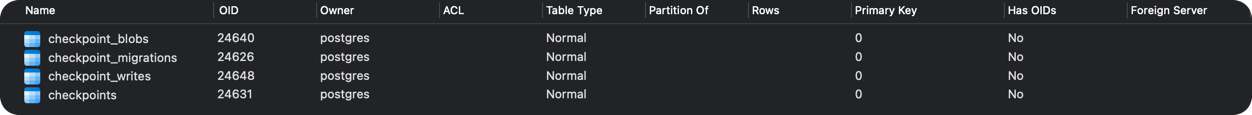

这四张表都是 setup() 函数初始化时创建的。
- checkpoints ：这是主表，存每个 thread 在某个时刻的 checkpoint 快照。
- checkpoint_blobs ：这张表专门存不适合直接内联进 checkpoints.checkpoint 的较复杂channel 值。
- checkpoint_writes ：这张表存的是中间写入 / pending writes，不是最终完整 checkpoint。
- checkpoint_migrations ：这张表不是业务数据表，而是迁移版本表。

## 3、对比两种方式

总结：
1. InMemorySaver()将状态持久化到内存， 进程结束或重建Saver() 则历史状态丢失
2. 基于外部存储介质（如PostgreSQL）的持久化器，其存储的状态不会随进程终止而丢失，只要 不显式删除历史状态 ，即可通过 thread_id 加载历史状态。